# AI4I 2020 exploratory data analysis

This is **step 2 of the project plan**. We will inspect the data before splitting it or training a model.

Questions to answer:

1. What does each column represent, and is the file complete?
2. How rare are failures?
3. How do the five numeric inputs differ between failure and no-failure observations?
4. Which measurements move together?
5. What data-quality or evaluation issues should we carry into the next step?

The [AI4I 2020 dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) is synthetic and licensed under CC BY 4.0. Each row is a process observation. The original overall label is `Machine failure`: `0` means no failure and `1` means failure. Our chosen modeling target is **`Failure evidence`**, the row-wise OR of that original label and all five failure-mode flags. This is an annotation-policy assumption, not a verified correction of the original labels; section 8 documents the decision and its effect. There is no defined future failure horizon.

**Scope:** explore the complete uploaded file, preserve its labels and values, and use only the six allowed inputs when examining predictors. This full-file exploration must be disclosed in later model evaluation; a subsequent test partition will not have been completely unseen with respect to EDA decisions.

## 1. Load the data and identify the inputs

Run the cells from top to bottom. The setup finds the repository from either its root or the `notebooks/` directory. It loads the existing project functions from `src/`, so an editable package installation is optional for this notebook.

We retain all raw columns for auditing. The feature allowlist gives us **five numeric measurements plus product type**. Identifiers and failure-mode flags are excluded from model inputs.

In [1]:
from pathlib import Path
import hashlib
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
        and (path / "src" / "maintain_predict").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from the maintain-predict repository.")

source_directory = str(project_root / "src")
if source_directory not in sys.path:
    sys.path.insert(0, source_directory)

from maintain_predict.data import load_readings
from maintain_predict.features import (
    FAILURE_FLAG_COLUMNS,
    FEATURE_COLUMNS,
    SOURCE_TARGET_COLUMN,
    TARGET_COLUMN,
    TARGET_POLICY,
    select_features_and_target,
)

data_path = project_root / "data" / "ai4i2020.csv"
if not data_path.is_file():
    raise FileNotFoundError("Place ai4i2020.csv in the project's data/ directory.")

source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
readings = load_readings(data_path)
features, target = select_features_and_target(readings)
source_target = readings[SOURCE_TARGET_COLUMN].copy()
analysis_readings = readings.assign(**{TARGET_COLUMN: target})

ID_COLUMNS = ["UDI", "Product ID"]
FAILURE_FLAGS = list(FAILURE_FLAG_COLUMNS)
SENSOR_COLUMNS = [column for column in FEATURE_COLUMNS if column != "Type"]
OUTCOME_LABELS = {0: "No failure evidence", 1: "Failure evidence"}
SOURCE_OUTCOME_LABELS = {0: "Original no failure", 1: "Original failure"}
COLORS = {0: "#2870A5", 1: "#BD493B"}
SENSOR_LABELS = {
    "Air temperature [K]": "Air temperature (K)",
    "Process temperature [K]": "Process temperature (K)",
    "Rotational speed [rpm]": "Rotational speed (rpm)",
    "Torque [Nm]": "Torque (Nm)",
    "Tool wear [min]": "Tool wear (min)",
}

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 35)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

print(f"Loaded {len(readings):,} observations and {readings.shape[1]} columns.")
print("Inputs:", list(features.columns))
print("Model target:", TARGET_COLUMN, "| policy:", TARGET_POLICY)
print("Source SHA-256:", source_sha256)
display(pd.Series({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": matplotlib.__version__,
}, name="Execution environment"))
display(readings.head())

Loaded 10,000 observations and 14 columns.
Inputs: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Model target: Failure evidence | policy: failure_evidence_or_v1
Source SHA-256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


Python        3.14.3
pandas         2.3.3
NumPy          2.4.4
Matplotlib    3.10.8
Name: Execution environment, dtype: object

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Column roles, types, missing values, and duplicates

The stored data type tells us how pandas read a column. Its role tells us how to use it. For example, `UDI` is numeric but is an identifier, while `Type` is a categorical input.

An exact duplicate check on the whole file is not enough: unique IDs could hide repeated readings. We also check duplicates after removing IDs and on the six allowed inputs alone.

In [2]:
column_roles = {
    **{column: "Identifier: exclude from inputs" for column in ID_COLUMNS},
    **{column: "Numeric input" for column in SENSOR_COLUMNS},
    "Type": "Categorical input",
    SOURCE_TARGET_COLUMN: "Original overall label; retained unchanged",
    **{column: "Outcome flag: exclude from inputs" for column in FAILURE_FLAGS},
}

schema = pd.DataFrame({
    "role": pd.Series(column_roles),
    "dtype": readings.dtypes.astype(str),
    "missing": readings.isna().sum(),
    "unique values": readings.nunique(dropna=False),
}).loc[readings.columns]
display(schema)

numeric_values = readings.select_dtypes(include="number").to_numpy()
binary_columns = [SOURCE_TARGET_COLUMN, *FAILURE_FLAGS]
quality_checks = pd.Series({
    "Missing cells": int(readings.isna().sum().sum()),
    "Nonfinite numeric cells": int((~np.isfinite(numeric_values)).sum()),
    "Duplicate complete rows": int(readings.duplicated().sum()),
    "Duplicates excluding both IDs": int(readings.drop(columns=ID_COLUMNS).duplicated().sum()),
    "Duplicate feature combinations": int(features.duplicated().sum()),
    "Invalid product types": int((~readings["Type"].isin(["L", "M", "H"])).sum()),
    "Nonbinary outcome values": int((~readings[binary_columns].isin([0, 1])).sum().sum()),
    "Product prefix / Type disagreements": int(
        readings["Product ID"].str[0].ne(readings["Type"]).sum()
    ),
}, name="Count")
display(quality_checks.to_frame())

excluded_columns = {*ID_COLUMNS, SOURCE_TARGET_COLUMN, TARGET_COLUMN, *FAILURE_FLAGS}
assert excluded_columns.isdisjoint(features.columns), "Outcome or ID leakage in inputs."
assert tuple(features.columns) == FEATURE_COLUMNS
if not readings[binary_columns].isin([0, 1]).all().all():
    raise ValueError("Resolve nonbinary outcomes before running the grouped analysis.")

,role,dtype,missing,unique values
UDI,Identifier: exclude from inputs,int64,0,10000
Product ID,Identifier: exclude from inputs,object,0,10000
Type,Categorical input,object,0,3
Air temperature [K],Numeric input,float64,0,93
Process temperature [K],Numeric input,float64,0,82
Rotational speed [rpm],Numeric input,int64,0,941
Torque [Nm],Numeric input,float64,0,577
Tool wear [min],Numeric input,int64,0,246
Machine failure,Original overall label; retained unchanged,int64,0,2
TWF,Outcome flag: exclude from inputs,int64,0,2


,Count
Missing cells,0
Nonfinite numeric cells,0
Duplicate complete rows,0
Duplicates excluding both IDs,0
Duplicate feature combinations,0
Invalid product types,0
Nonbinary outcome values,0
Product prefix / Type disagreements,0


## 3. What ranges do the sensors cover?

`25%`, `50%`, and `75%` are the lower quartile, median, and upper quartile. The middle half of readings lies between the two quartiles. The standard deviation summarizes spread.

These are observed ranges in this synthetic file, not established operating limits for real equipment. Temperatures are in Kelvin; subtract 273.15 to convert them to Celsius.

In [3]:
sensor_summary = features[SENSOR_COLUMNS].describe().T
display(sensor_summary.round(2))

# The IQR rule highlights unusual values, not necessarily bad measurements.
outlier_rows = []
for column in SENSOR_COLUMNS:
    q1, q3 = features[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = round(float(q1 - 1.5 * iqr), 10)
    upper = round(float(q3 + 1.5 * iqr), 10)
    unusual = features[column].lt(lower) | features[column].gt(upper)
    outlier_rows.append({
        "measurement": SENSOR_LABELS[column],
        "lower IQR fence": lower,
        "upper IQR fence": upper,
        "unusual readings": int(unusual.sum()),
        "failures among them": int(target.loc[unusual].sum()),
    })
iqr_summary = pd.DataFrame(outlier_rows).set_index("measurement")
display(iqr_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


,lower IQR fence,upper IQR fence,unusual readings,failures among them
measurement,,,,
Air temperature (K),293.50,306.30,0,0
Process temperature (K),305.35,314.55,0,0
Rotational speed (rpm),1139.50,1895.50,418,35
Torque (Nm),12.80,67.20,64,58
Tool wear (min),-110.50,325.50,0,0


Extreme torque readings contain many failures. We keep them: deleting all statistical outliers could remove the behavior we want a model to recognize. The rounded IQR fences avoid floating-point boundary noise when a measurement equals a fence.

## 4. How rare are failures?

Class balance is the fraction of observations in each target class. Here the classes use our derived `Failure evidence` target. The original `Machine failure` label is retained separately, and section 8 compares the two definitions. We show the counts and percentages explicitly because the failure class is much smaller. A high overall accuracy can be achieved by ignoring it.

,observations,share (%)
Failure evidence,,
No failure evidence,9643,96.43
Failure evidence,357,3.57


Exact observed failure-evidence prevalence: 357/10,000 = 3.57%
Always predicting no failure evidence would give 96.43% accuracy and catch no failures.


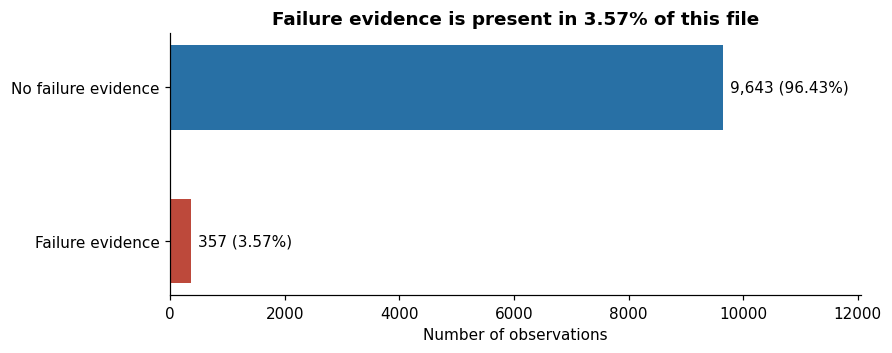

In [4]:
class_counts = target.value_counts().reindex([0, 1], fill_value=0)
failure_rate = float(target.mean())
class_balance = pd.DataFrame({
    "observations": class_counts,
    "share (%)": class_counts / len(target) * 100,
}).rename(index=OUTCOME_LABELS)
display(class_balance.round(2))
print(f"Exact observed failure-evidence prevalence: {class_counts.loc[1]:,}/{len(target):,} = {failure_rate:.2%}")
print(f"Always predicting no failure evidence would give {1 - failure_rate:.2%} accuracy and catch no failures.")

fig, ax = plt.subplots(figsize=(8, 3.1), layout="constrained")
positions = np.arange(2)
ax.barh(positions, class_counts.to_numpy(), color=[COLORS[0], COLORS[1]], height=0.55)
ax.set_yticks(positions, [OUTCOME_LABELS[value] for value in [0, 1]])
ax.invert_yaxis()
ax.set_xlim(0, class_counts.max() * 1.25)
ax.set_xlabel("Number of observations")
ax.set_title(f"Failure evidence is present in {failure_rate:.2%} of this file")
for position, count in zip(positions, class_counts):
    ax.text(count + len(target) * 0.012, position, f"{count:,} ({count / len(target):.2%})", va="center")
plt.show()

## 5. Does product type matter?

Failure **count** and failure **rate** answer different questions. A common product category can contribute many failures simply because it has more observations. Divide failures by the number of readings within each category before comparing their rates.

,observations,failures,failure_rate_pct
Type,,,
L,6000,247,4.12
M,2997,85,2.84
H,1003,25,2.49


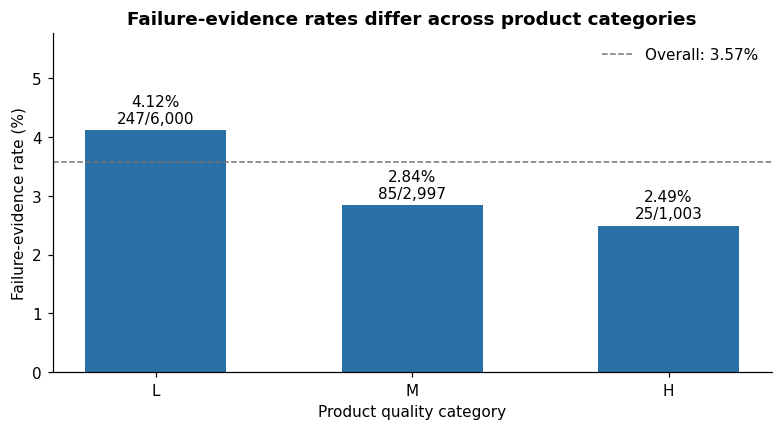

In [5]:
by_type = (
    analysis_readings.groupby("Type")[TARGET_COLUMN]
    .agg(observations="size", failures="sum", failure_rate="mean")
    .reindex(["L", "M", "H"])
)
display(by_type.assign(failure_rate_pct=by_type["failure_rate"] * 100).drop(columns="failure_rate").round(2))

fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
rates_pct = by_type["failure_rate"] * 100
ax.bar(by_type.index, rates_pct, color=COLORS[0], width=0.55)
ax.axhline(failure_rate * 100, color="0.45", linestyle="--", linewidth=1, label=f"Overall: {failure_rate:.2%}")
ax.set_ylim(0, rates_pct.max() * 1.4)
ax.set_xlabel("Product quality category")
ax.set_ylabel("Failure-evidence rate (%)")
ax.set_title("Failure-evidence rates differ across product categories")
for i, (category, group) in enumerate(by_type.iterrows()):
    ax.text(i, group["failure_rate"] * 100 + 0.12,
            f"{group['failure_rate']:.2%}\n{int(group['failures']):,}/{int(group['observations']):,}",
            ha="center")
ax.legend(frameon=False)
plt.show()

L has the highest observed rate, and H the lowest. This is an association in the file, not proof that product quality alone causes the difference. H contains only 25 failure-evidence positives, which will make later subgroup evaluation limited.

## 6. Sensor distributions, split by failure-evidence status

We compare every numeric input between the two classes. Each histogram is normalized separately within its class, so its total area is 1. That lets us compare shapes despite the 9,643-to-357 imbalance; equal areas do not mean equal class counts.

First compare class means and medians. A mean can be pulled by a long tail, while the median identifies the middle observation.

In [6]:
by_failure = analysis_readings.groupby(TARGET_COLUMN)[SENSOR_COLUMNS].agg(["mean", "median"]).T
by_failure.columns = [OUTCOME_LABELS[value] for value in by_failure.columns]
display(by_failure.round(2))

No failure evidence  Failure evidence
Air temperature [K]     mean                 299.97            300.88
                        median               300.00            301.60
Process temperature [K] mean                 309.99            310.31
                        median               310.00            310.50
Rotational speed [rpm]  mean                1540.35           1496.13
                        median              1507.00           1366.00
Torque [Nm]             mean                  39.62             49.83
                        median                39.80             53.20
Tool wear [min]         mean                 106.67            142.58
                        median               107.00            163.00

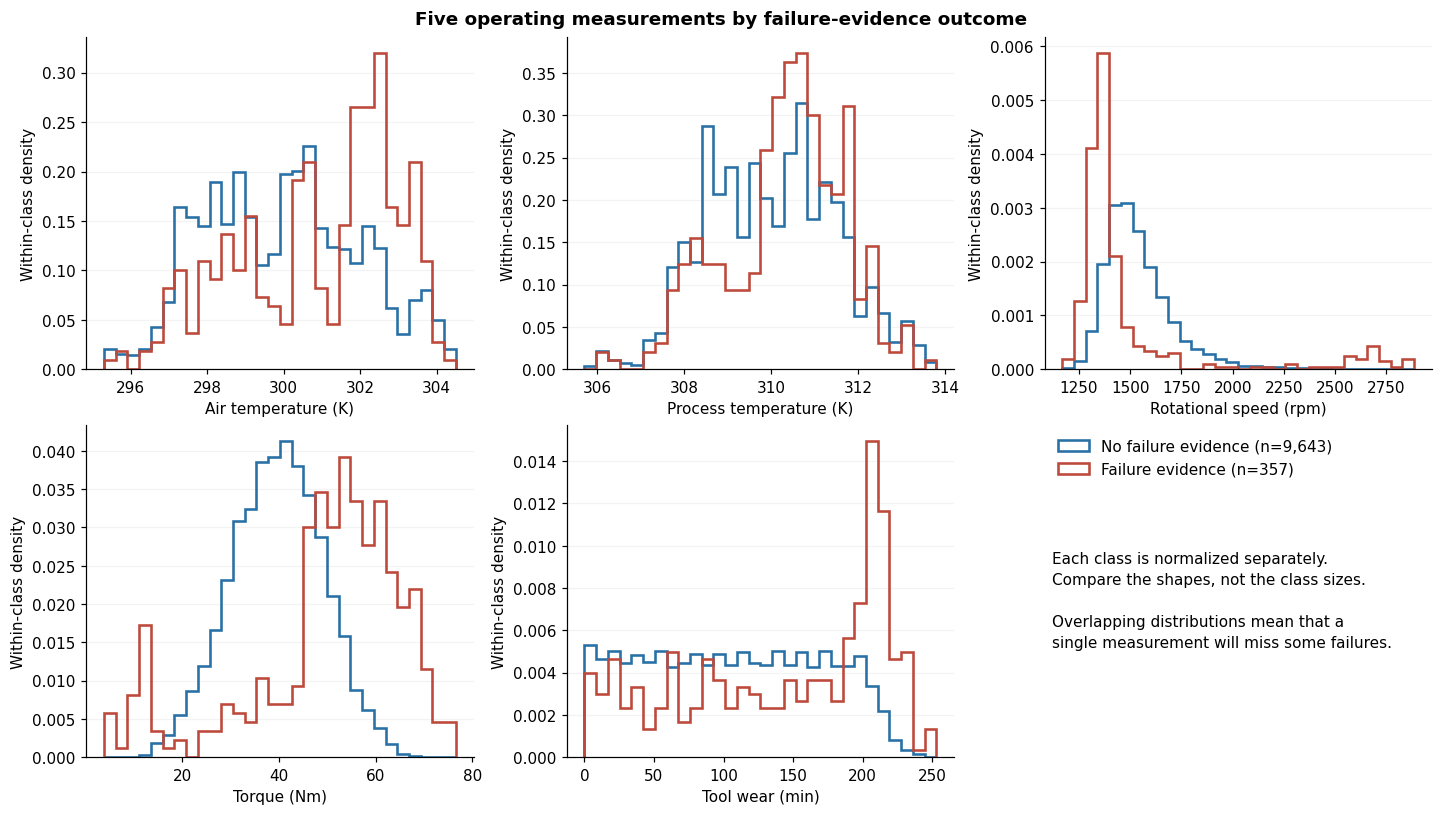

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.3), layout="constrained")
for ax, column in zip(axes.flat, SENSOR_COLUMNS):
    values = features[column]
    bins = np.linspace(values.min(), values.max(), 31)
    for outcome in [0, 1]:
        ax.hist(
            features.loc[target.eq(outcome), column],
            bins=bins,
            density=True,
            histtype="step",
            linewidth=1.7,
            color=COLORS[outcome],
            label=f"{OUTCOME_LABELS[outcome]} (n={class_counts.loc[outcome]:,})",
        )
    ax.set_xlabel(SENSOR_LABELS[column])
    ax.set_ylabel("Within-class density")
    ax.grid(axis="y", alpha=0.15)

legend_ax = axes.flat[-1]
legend_ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, frameon=False, loc="upper left")
legend_ax.text(0.02, 0.62,
               "Each class is normalized separately.\nCompare the shapes, not the class sizes.\n\nOverlapping distributions mean that a\nsingle measurement will miss some failures.",
               transform=legend_ax.transAxes, va="top", linespacing=1.5)
fig.suptitle("Five operating measurements by failure-evidence outcome", fontweight="bold")
plt.show()

Failures tend to have higher torque and more accumulated tool wear. Speed has a lower failure median and a high-speed failure tail. There are also failures at low torque, so a simple assumption that risk always increases with torque would be incomplete. The temperature distributions overlap substantially.

## 7. Which sensors move together?

Pearson correlation measures a **linear** association, from −1 to +1. Positive values indicate measurements tend to rise together; negative values indicate one tends to fall as the other rises. A value near zero does not rule out nonlinear relationships or useful interactions. Correlation does not establish causation.

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.000,0.876,0.023,-0.014,0.014
Process temperature [K],0.876,1.000,0.019,-0.014,0.013
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003
Tool wear [min],0.014,0.013,0.000,-0.003,1.000


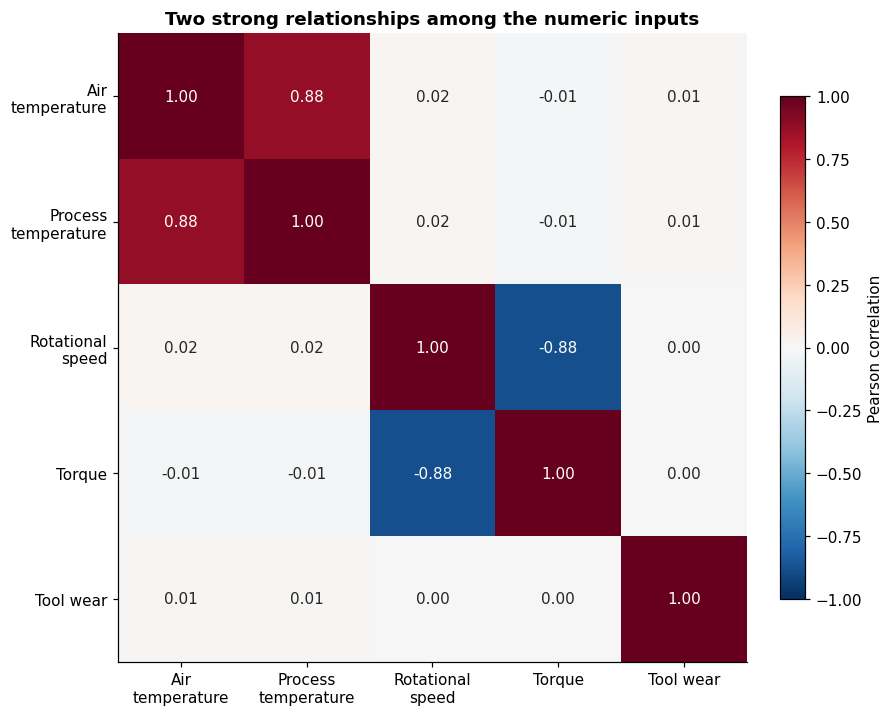

In [8]:
sensor_correlations = features[SENSOR_COLUMNS].corr(method="pearson")
display(sensor_correlations.round(3))

fig, ax = plt.subplots(figsize=(8, 6.4), layout="constrained")
image = ax.imshow(sensor_correlations, vmin=-1, vmax=1, cmap="RdBu_r")
short_names = ["Air\ntemperature", "Process\ntemperature", "Rotational\nspeed", "Torque", "Tool wear"]
ax.set_xticks(range(len(SENSOR_COLUMNS)), short_names)
ax.set_yticks(range(len(SENSOR_COLUMNS)), short_names)
for row in range(len(SENSOR_COLUMNS)):
    for column in range(len(SENSOR_COLUMNS)):
        value = float(sensor_correlations.iloc[row, column])
        label = f"{0 if abs(value) < 0.005 else value:.2f}"
        ax.text(column, row, label, ha="center", va="center",
                color="white" if abs(value) > 0.65 else "0.15")
fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Two strong relationships among the numeric inputs")
plt.show()

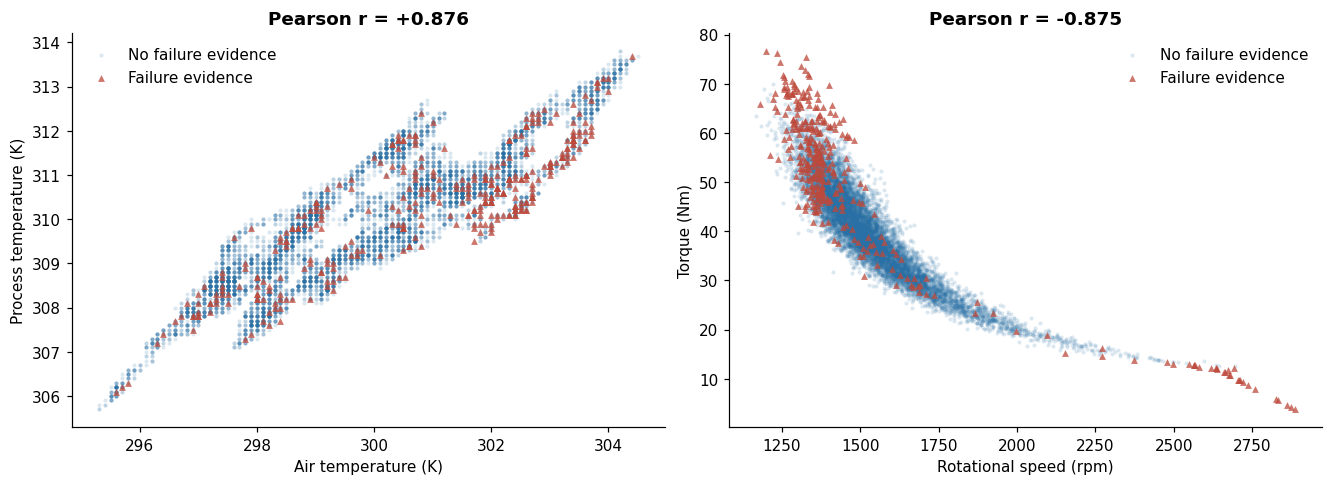

In [9]:
pairs = [
    ("Air temperature [K]", "Process temperature [K]"),
    ("Rotational speed [rpm]", "Torque [Nm]"),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
for ax, (x_column, y_column) in zip(axes, pairs):
    for outcome in [0, 1]:
        group = features.loc[target.eq(outcome)]
        ax.scatter(
            group[x_column], group[y_column],
            s=7 if outcome == 0 else 20,
            alpha=0.16 if outcome == 0 else 0.75,
            marker="o" if outcome == 0 else "^",
            color=COLORS[outcome], linewidths=0,
            label=OUTCOME_LABELS[outcome],
        )
    ax.set_xlabel(SENSOR_LABELS[x_column])
    ax.set_ylabel(SENSOR_LABELS[y_column])
    ax.set_title(f"Pearson r = {sensor_correlations.loc[x_column, y_column]:+.3f}")
    ax.legend(frameon=False)
plt.show()

Air and process temperatures co-move (`r ≈ +0.876`). Speed and torque move in opposite directions (`r ≈ −0.875`), with a visibly curved relationship. These observations motivate the plan's later temperature-difference and mechanical-power experiments. We have not yet engineered features or tested whether they improve a model.

## 8. Audit the overall label against the failure-mode flags

The intended rule is that the overall label is positive when at least one failure mode is positive. Multiple failure modes can overlap. We compare that rule with the actual file rather than assuming it holds perfectly.

The flags are used for source-label auditing and for defining our derived target. They are never predictor inputs. This audit deliberately compares the **original** `Machine failure` column with the flags, so the raw inconsistencies remain visible even though the model uses a separate target.

In [10]:
any_mode_flag = readings[FAILURE_FLAGS].eq(1).any(axis=1)
source_positive = source_target.eq(1)
failure_without_flag = source_positive & ~any_mode_flag
flag_without_failure = ~source_positive & any_mode_flag
label_disagreement = source_positive.ne(any_mode_flag)

label_consistency = (
    pd.crosstab(source_target, any_mode_flag)
    .reindex(index=[0, 1], columns=[False, True], fill_value=0)
    .rename(index=SOURCE_OUTCOME_LABELS,
            columns={False: "No mode flag", True: "Any mode flag"})
)
display(label_consistency)

flag_summary = pd.DataFrame({
    "flag-positive rows": readings[FAILURE_FLAGS].sum(),
    "original Machine failure = 1": readings.loc[source_positive, FAILURE_FLAGS].sum(),
    "original Machine failure = 0": readings.loc[~source_positive, FAILURE_FLAGS].sum(),
})
display(flag_summary)
print(f"Original overall failure with no mode flag: {failure_without_flag.sum():,}")
print(f"Mode flag with no original overall failure: {flag_without_failure.sum():,}")
print(f"Original-label disagreements: {label_disagreement.sum():,} ({label_disagreement.mean():.2%})")

review_rows = readings.loc[label_disagreement, ["UDI", SOURCE_TARGET_COLUMN, *FAILURE_FLAGS]]
display(review_rows)

col_0,No mode flag,Any mode flag
Machine failure,,
Original no failure,9643,18
Original failure,9,330


,flag-positive rows,original Machine failure = 1,original Machine failure = 0
TWF,46,46,0
HDF,115,115,0
PWF,95,95,0
OSF,98,98,0
RNF,19,1,18


Original overall failure with no mode flag: 9
Mode flag with no original overall failure: 18
Original-label disagreements: 27 (0.27%)


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


### Chosen target policy: preserve any recorded positive

We adopt `failure_evidence_or_v1`:

```text
Failure evidence = Machine failure OR TWF OR HDF OR PWF OR OSF OR RNF
```

**Assumption:** a positive in either the overall label or any failure-mode flag is sufficient evidence for our chosen positive class. This keeps every original positive, including a failure with no recorded mode. It also promotes a flagged original negative. The rule is applied consistently to every row; the raw CSV and its original labels remain unchanged.

On this file, 18 RNF-positive original negatives are promoted, while the nine original positives without flags stay positive. There are **357 derived positives (3.57%)**, compared with **339 original positives (3.39%)**. Only 18 target values differ, even though the original label audit identifies 27 disagreements. Using the flags alone would instead produce 348 positives and discard those nine original positives; that is a different rule.

This is a documented outcome definition, not proof that the original labels were wrong. The increase in prevalence is a consequence rather than a justification. An RNF annotation records random failure evidence, which may be unpredictable from the available sensors. It can introduce positive cases with no learnable sensor pattern.

The flags help construct `y` and remain excluded from `X`. Before model development, freeze this policy for training, validation, and test data. Identify the derived target in all model results rather than presenting them as directly comparable to the original-label benchmark.

In [11]:
target_comparison = pd.DataFrame({
    "positives": [int(source_target.sum()), int(target.sum())],
    "negatives": [int(source_target.eq(0).sum()), int(target.eq(0).sum())],
    "positive rate (%)": [source_target.mean() * 100, target.mean() * 100],
}, index=pd.Index([SOURCE_TARGET_COLUMN, TARGET_COLUMN], name="Outcome definition"))
display(target_comparison.round(2))

promoted = source_target.eq(0) & target.eq(1)
demoted = source_target.eq(1) & target.eq(0)
assert target.eq(source_target.eq(1) | any_mode_flag).all()
assert not demoted.any()
assert TARGET_COLUMN not in readings.columns  # The original DataFrame is unchanged.

print("Target policy:", TARGET_POLICY)
print(f"Original positives: {int(source_target.sum()):,} ({source_target.mean():.2%})")
print(f"Derived positives: {int(target.sum()):,} ({target.mean():.2%})")
print(f"Promoted original negatives: {int(promoted.sum()):,}")
print(f"Demoted original positives: {int(demoted.sum()):,}")
print("Promoted record UDIs:", readings.loc[promoted, "UDI"].tolist())

,positives,negatives,positive rate (%)
Outcome definition,,,
Machine failure,339,9661,3.39
Failure evidence,357,9643,3.57


Target policy: failure_evidence_or_v1
Original positives: 339 (3.39%)
Derived positives: 357 (3.57%)
Promoted original negatives: 18
Demoted original positives: 0
Promoted record UDIs: [1222, 1303, 1749, 2073, 2560, 3066, 3453, 5472, 5490, 5496, 5510, 5554, 5640, 6092, 6914, 6961, 7489, 7869]


The original source-label audit still identifies 9 unflagged failures and 18 RNF-positive nonfailures. The original column is preserved. Outcome-grouped analysis below uses the derived target.

## 9. Does original row order contain structure?

UDI is an identifier and stays outside the input features. It is also a convenient way to examine the original file order. It is **not a timestamp**.

Lag-one correlation compares each sensor reading with the next reading. Strong similarity between adjacent rows matters when deciding what a random split can tell us about generalization to different operating conditions.

In [12]:
lag_one = pd.Series({
    SENSOR_LABELS[column]: readings[column].autocorr(lag=1)
    for column in SENSOR_COLUMNS
}, name="Adjacent-row correlation")
display(lag_one.round(4).to_frame())

# Use row positions for blocks, preserving the CSV's existing order.
row_position = pd.Series(np.arange(1, len(readings) + 1), index=readings.index)
block_number = ((row_position - 1) // 1000 + 1).rename("Source-row block")
row_blocks = analysis_readings.groupby(block_number)[TARGET_COLUMN].agg(
    observations="size", failures="sum", failure_rate="mean"
)
display(row_blocks.assign(failure_rate_pct=row_blocks["failure_rate"] * 100)
        .drop(columns="failure_rate").round(2))
print("UDI follows file order:", np.array_equal(readings["UDI"].to_numpy(), row_position.to_numpy()))
print("Decreases in tool wear between adjacent rows:", int(readings["Tool wear [min]"].diff().lt(0).sum()))

,Adjacent-row correlation
Air temperature (K),0.9994
Process temperature (K),0.9985
Rotational speed (rpm),0.0077
Torque (Nm),0.0054
Tool wear (min),0.9306


,observations,failures,failure_rate_pct
Source-row block,,,
1,1000,23,2.3
2,1000,32,3.2
3,1000,24,2.4
4,1000,29,2.9
5,1000,134,13.4
6,1000,26,2.6
7,1000,26,2.6
8,1000,24,2.4
9,1000,17,1.7


UDI follows file order: True
Decreases in tool wear between adjacent rows: 119


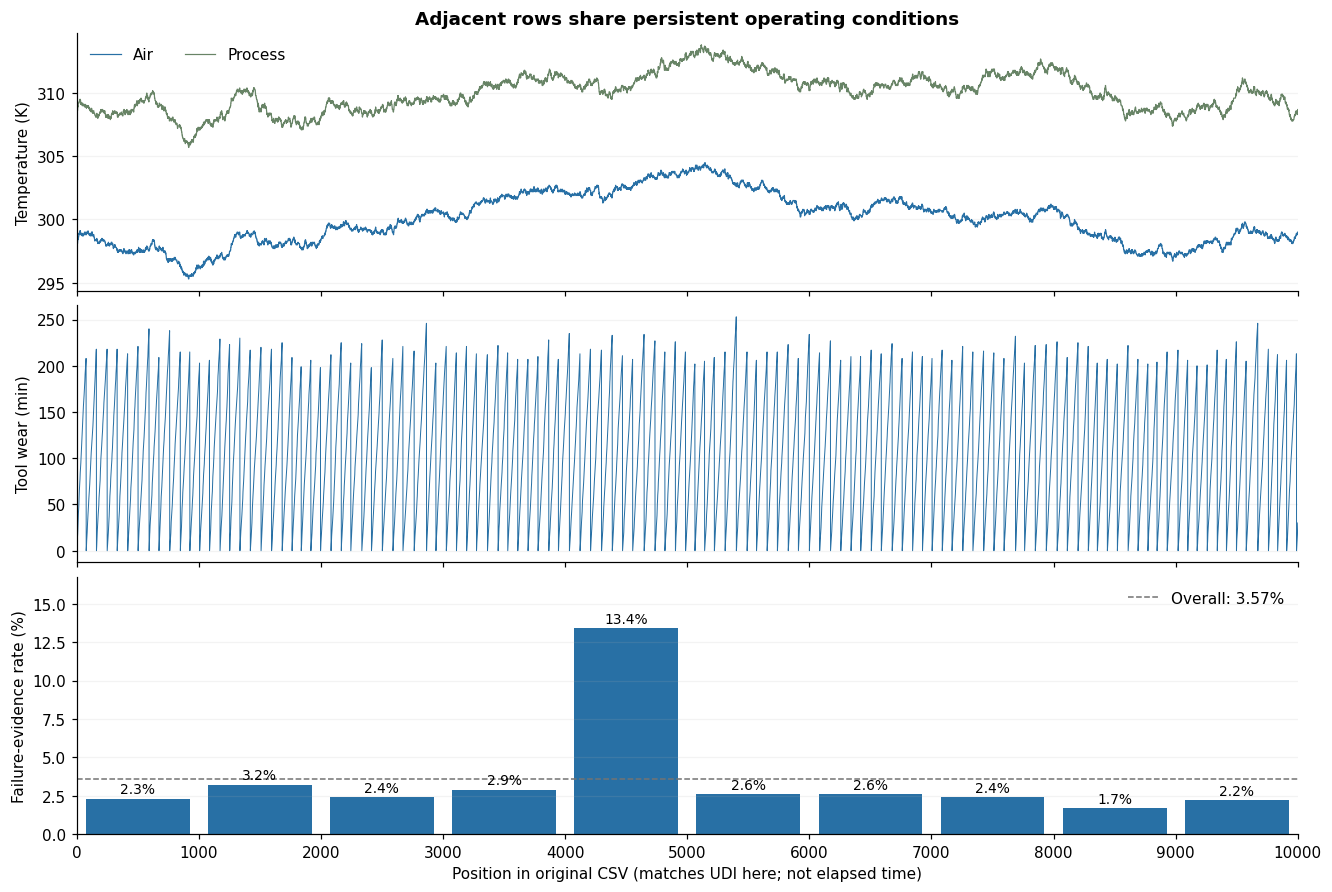

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
axes[0].plot(row_position, readings["Air temperature [K]"], linewidth=0.8, color=COLORS[0], label="Air")
axes[0].plot(row_position, readings["Process temperature [K]"], linewidth=0.8, color="#688466", label="Process")
axes[0].set_ylabel("Temperature (K)")
axes[0].legend(frameon=False, ncol=2, loc="upper left")
axes[0].set_title("Adjacent rows share persistent operating conditions")

axes[1].plot(row_position, readings["Tool wear [min]"], linewidth=0.65, color=COLORS[0])
axes[1].set_ylabel("Tool wear (min)")

block_centers = [(index - 1) * 1000 + group["observations"] / 2 + 0.5
                 for index, group in row_blocks.iterrows()]
block_rates_pct = row_blocks["failure_rate"] * 100
axes[2].bar(block_centers, block_rates_pct, width=850, color=COLORS[0])
axes[2].axhline(failure_rate * 100, color="0.45", linestyle="--", linewidth=1, label=f"Overall: {failure_rate:.2%}")
axes[2].set_ylabel("Failure-evidence rate (%)")
axes[2].set_xlabel("Position in original CSV (matches UDI here; not elapsed time)")
axes[2].set_ylim(0, block_rates_pct.max() * 1.25)
axes[2].legend(frameon=False, loc="upper right")
for center, rate in zip(block_centers, block_rates_pct):
    axes[2].text(center, rate + 0.35, f"{rate:.1f}%", ha="center", fontsize=9)
axes[2].set_xticks(np.arange(0, len(readings) + 1, 1000))
axes[2].set_xlim(0, len(readings) + 1)
for ax in axes:
    ax.grid(axis="y", alpha=0.15)
plt.show()

## What we carry into the next step

The next exercise is a manual 70/15/15 split with random_state=42, jointly stratified by Type and Failure evidence. Tool wear remains a numeric input, without low/high splitting groups. Read [the seven-step split script](../scripts/01_split_data.py) and [the splitting guide](../docs/splitting_guide.md), then run the script yourself. It has not yet been executed on the uploaded dataset; baseline training remains a later exercise. The feature allowlist remains the same six inputs. The chosen target policy is `failure_evidence_or_v1`: any positive in the original overall label or a mode flag makes the derived target positive. Keep the original column for traceability and identify the derived definition in model metrics, MLflow runs, and the model card.

Fit preprocessing only within training data and keep validation/test data out of fitting and hyperparameter searches. Apply the same frozen target rule across every partition. Do not select a target policy because it produces better test metrics or more positive cases.

A random split will benchmark new readings from the same synthetic mixture. Declare a separate row-block sensitivity analysis to investigate changing operating conditions. Do not call this a true chronological or machine-level evaluation: there are no timestamps or repeated machine identifiers. Disclose that whole-file EDA was already performed.

No raw values were changed, no rows were removed, and no split, model fit, or threshold selection was performed. The derived target exists separately in memory; the CSV retains its original 14 columns.

## Five observations in plain words

1. **Failure evidence is rare:** the derived rule labels 357 of 10,000 readings positive, exactly **3.57%**, compared with 339 original positives (3.39%). Always predicting no failure evidence would give 96.43% accuracy and miss every positive, so accuracy alone remains misleading.
2. **Positive evidence tends to occur under greater load and usage:** median torque is 53.2 Nm for derived positives versus 39.8 Nm for negatives, and median wear is 163 versus 107 minutes. The distributions still overlap, including positive cases at low torque or high speed.
3. **Two sensor pairs move together:** air and process temperatures have correlation about +0.876, while speed and torque have correlation about −0.875. Their combinations are worth testing later; correlation does not prove causation or model improvement.
4. **A complete file can still contain conflicting annotations:** there are no missing cells or duplicate feature combinations, but 27 original-label/flag disagreements. The chosen OR rule promotes 18 original negatives and retains the nine original unflagged positives. This is an explicit assumption, not a verified correction; random failure evidence may not have a predictable sensor pattern.
5. **File order contains changing operating conditions:** rows 4,001–5,000 contain 134 derived positives, about 37.54% of all derived positives in just 10% of the data. Adjacent temperatures are strongly related, so randomly mixing adjacent rows may give a more optimistic picture than evaluation across separate operating regimes.